# Comparing Distances
The purpose of this notebook is to compare the various types of distance between copulas to get a better understanding of how the choice of the copula-constrained Wasserstein distance affects the resulting geometry. 

The code in this notebook was implemented using Claude Code.

To compare the other distance types with the absolute difference in correlation coefficients (both $\rho$ and $\tau$), these first have to be computed.

According to Nelsen's Introduction to Copulas (2006, Th. 5.1.6 and Th. 5.1.3), Spearman's $\rho$ and Kendall's $\tau$ for each of the copulas in the MDS map can be determined as follows:

$$\rho = 12 \iint_{[0,1]^2} C(u,v)\,du\,dv - 3, \qquad \tau = 1 - 4 \iint_{[0,1]^2} \frac{\partial C}{\partial u}\,\frac{\partial C}{\partial v}\,du\,dv .$$

Both integrals are evaluated with the midpoint rule on a $256 \times 256$ grid, using the joint CDF (`cdf_u`) and the two h-functions (`hfunc_u`, `hfunc_v`).

In [1]:
# the 101 copulas, named and built exactly as in distance_correlations.ipynb
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch

sys.path.insert(0, str(Path.cwd().parent))  # project root, so the distance_calculation_campaign imports resolve

from distance_calculation_campaign import unique_pairs as up
from distance_calculation_campaign.copula_families import GluedCopula, MirroredCopula, TransposedCopula

# every shape with the isometry variants its category keeps (the others are copies)
VARIANTS = {0: ["", "!M0", "!M1", "!M01", "!T", "!T!M0", "!T!M1", "!T!M01"],
            1: ["", "!M0", "!M1", "!M01"], 2: ["", "!M0"],
            3: ["", "!M1", "!T", "!T!M0"], 4: [""]}
keep = [s + v for c in range(5) for s in getattr(up, f"unique_shapes_category_{c}")
        for v in VARIANTS[c]]
cats = np.array([up.get_cat(n.split("!")[0]) for n in keep])

iso = {"M0": lambda c: MirroredCopula(c, 0), "M1": lambda c: MirroredCopula(c, 1),
       "M01": lambda c: MirroredCopula(c, (0, 1)), "T": TransposedCopula}

def build(name):                        # tags applied left to right, as in run_pair_queue
    head, *tags = name.split("!")
    c = up.unique_shapes[head]
    for t in tags:
        c = iso[t](c)
    return c

print(len(keep), "copulas")

101 copulas


In [2]:
N = 256

x = (np.arange(N) + 0.5) / N                # cell midpoints
grid = torch.tensor(np.stack(np.meshgrid(x, x, indexing="ij"), -1).reshape(-1, 2))

def rank_correlations(c):
    # a glued copula's h-functions jump across its seam, so the seam must lie on a cell edge
    for m in c.modules():
        if isinstance(m, GluedCopula):
            assert (m.cut * N).is_integer(), f"seam at {m.cut} is not on the grid"
    with torch.no_grad():
        mean_C = c.cdf_u(grid).double().mean().item()
        mean_hh = (c.hfunc_u(grid) * c.hfunc_v(grid)).double().mean().item()
    return 12 * mean_C - 3, 1 - 4 * mean_hh

rows = []
for name, cat in zip(keep, cats):
    rho, tau = rank_correlations(build(name))
    rows.append(dict(copula=name, category=cat, rho=rho, tau=tau))
res = pd.DataFrame(rows).set_index("copula")

res.to_csv("correlations_and_corner_densities.csv")
pd.set_option("display.max_rows", 120)
res.round(2)

,category,rho,tau
copula,,,
(khoudraji_gumbel6_0.4),0,0.67,0.53
(khoudraji_gumbel6_0.4)!M0,0,-0.67,-0.53
(khoudraji_gumbel6_0.4)!M1,0,-0.67,-0.53
(khoudraji_gumbel6_0.4)!M01,0,0.67,0.53
(khoudraji_gumbel6_0.4)!T,0,0.67,0.53
(khoudraji_gumbel6_0.4)!T!M0,0,-0.67,-0.53
(khoudraji_gumbel6_0.4)!T!M1,0,-0.67,-0.53
(khoudraji_gumbel6_0.4)!T!M01,0,0.67,0.53
(khoudraji_gaussian0.9_0.4),0,0.62,0.46


Using each of the copulas' correlation coefficients, we next calculate the absolute difference in correlation coefficients for each copula pair.

In [3]:
# per campaign pair: how far apart the two endpoints' rank correlations are,
# written into unique_pairs.json as rho_diff / tau_diff
import json

with open("../distance_calculation_campaign/unique_pairs.json") as f:
    pairs = json.load(f)

for p in pairs:
    c0, c1 = p["pair"].split("/")
    p["rho_diff"] = abs(res.rho[c0] - res.rho[c1])
    p["tau_diff"] = abs(res.tau[c0] - res.tau[c1])

with open("../distance_calculation_campaign/unique_pairs.json", "w") as f:
    json.dump(pairs, f, indent=2)

pd.DataFrame(pairs).set_index("pair")[["rho_diff", "tau_diff"]].round(2)

,rho_diff,tau_diff
pair,,
(clayton10)/(gaussian0.9),0.07,0.12
(frank10)/(studentt0.8_2),0.10,0.08
(khoudraji_gumbel6_0.4)/(khoudraji_gumbel6_0.4)!M1,1.34,1.06
(joe6)/(glued_khoudraji_clayton8@u1_u0u1),0.89,0.72
(mix_clayton10_clayton10@u0u1)/(glued_frank8@u0_frank8),0.96,0.83
...,...,...
(mix_clayton4_clayton4@u0u1)/(glued_frank8@u0_frank8),0.85,0.66
(khoudraji_gaussian0.9_0.4)/(gumbel2)!M1,1.30,0.96
(mix_gaussian0.6_clayton10_50)/(gumbel4),0.14,0.16


While learning velocity fields to calculate the copula-constrained Wasserstein distances between unique copula pairs, 42 out of 58 copula pairs containing a Gaussian copula with $\rho = 0.99$ did not terminate before reaching the maximum amount of iterations. They seem to have mass too concentrated to be reliably learned, so they are excluded going forward.

In [5]:
# drop every pair with a gaussian(0.99) endpoint, in any isometry variant
pairs = pd.DataFrame(pairs)
pairs = pairs[~pairs["pair"].str.contains("(gaussian0.99)", regex=False)]
print(len(pairs), "pairs left")

987 pairs left


The sample-based Wasserstein distance calculation method used int `run_pair_queue.py` is biased upwards, which becomes relevant particularly for pairs of copulas that are close together. We debias them using the estimated distance between a copula and itself, which should of course be $0$ if there was no bias.

In [22]:
# debias regular_W2 as in distance_correlations.ipynb: remove the sampling cost in
# quadrature, E[W2hat^2] ~ W2^2 + s^2. s is the W2 a copula scores against itself,
# measured here with the campaign's own regular_W2 (copied from run_pair_queue.py,
# which does not import on Windows): exact matching of two 5000-point samples, seed 0.
import math
import ot

def regular_W2(copula0, copula1, *, npts=5000, seed=0):
    np.random.seed(seed)
    u0 = copula0.sample_u(npts)
    u1 = copula1.sample_u(npts)
    M = ot.dist(u0, u1)
    a = np.ones(npts) / npts
    b = np.ones(npts) / npts
    return math.sqrt(ot.emd2(a, b, M, numItermax=1_000_000))

# one self-distance per shape (an isometry of the square doesn't change it), skipping
# gaussian0.99 like the filter above; averaged in squares, since s enters as s^2
shapes = sorted({n.split("!")[0] for n in keep} - {"(gaussian0.99)"})
s_self = pd.Series({n: regular_W2(build(n), build(n)) for n in shapes})
S_SELF = math.sqrt((s_self ** 2).mean())
print(f"S_SELF = {S_SELF:.4f} over {len(shapes)} shapes "
      f"(range {s_self.min():.4f} - {s_self.max():.4f})")

pairs["regular_W2_debiased"] = np.sqrt(np.clip(pairs["regular_W2"] ** 2 - S_SELF ** 2, 0, None))

c:\Users\nicol\bachelor_thesis\bsc_env\Lib\site-packages\statsmodels\tools\rng_qrng.py:54: FutureWarning: Passing `None` as the seed currently return the NumPy singleton RandomState
(np.random.mtrand._rand). After release 0.13 this will change to using the
default generator provided by NumPy (np.random.default_rng()). If you need
reproducible draws, you should pass a seeded np.random.Generator, e.g.,

import numpy as np
seed = 32839283923801
rng = np.random.default_rng(seed)"

  warnings.warn(_future_warn, FutureWarning)


S_SELF = 0.0179 over 30 shapes (range 0.0110 - 0.0223)


Next, we examine correlation matrix of the distance measures.

In [23]:
# correlations between the three distances and the two rank-correlation differences
cols = ["L2_fade_distance", "regular_W2_debiased", "copula_constrained_wasserstein",
        "rho_diff", "tau_diff"]
display(pairs[cols].corr())
display(pairs[cols].corr(method="spearman"))

,L2_fade_distance,regular_W2_debiased,copula_constrained_wasserstein,rho_diff,tau_diff
L2_fade_distance,1.000000,0.983928,0.991540,0.960823,0.976563
regular_W2_debiased,0.983928,1.000000,0.996436,0.988241,0.990959
copula_constrained_wasserstein,0.991540,0.996436,1.000000,0.977310,0.985672
rho_diff,0.960823,0.988241,0.977310,1.000000,0.994494
tau_diff,0.976563,0.990959,0.985672,0.994494,1.000000


,L2_fade_distance,regular_W2_debiased,copula_constrained_wasserstein,rho_diff,tau_diff
L2_fade_distance,1.000000,0.996382,0.998478,0.963807,0.969499
regular_W2_debiased,0.996382,1.000000,0.997309,0.974084,0.976158
copula_constrained_wasserstein,0.998478,0.997309,1.000000,0.965630,0.970721
rho_diff,0.963807,0.974084,0.965630,1.000000,0.995546
tau_diff,0.969499,0.976158,0.970721,0.995546,1.000000


To examine how the regular and copula-constrained Wasserstein distances relate, we create a scatter plot plotting their ratio.

949 endpoint pairs (38 with debiased W2 < 0.03 left out)


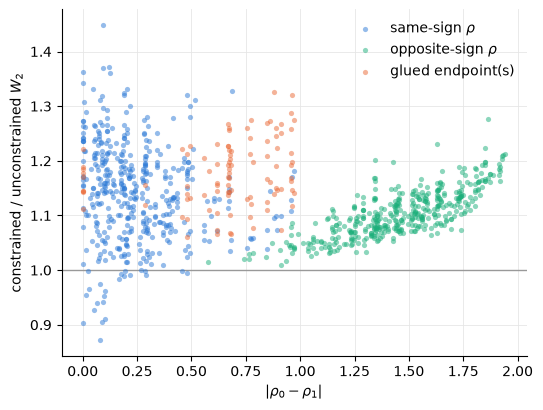

In [29]:
# constrained / debiased regular W2 against the rho difference of the two endpoints;
# the ratio is >= 1 wherever the lower bound holds. Pairs with debiased W2 < W2_MIN are
# left out: there the denominator is mostly sampling noise.
import matplotlib.pyplot as plt

W2_MIN = 0.03
ok = pairs["regular_W2_debiased"] >= W2_MIN
rho_diff = pairs.loc[ok, "rho_diff"]
ratio = pairs.loc[ok, "copula_constrained_wasserstein"] / pairs.loc[ok, "regular_W2_debiased"]
ends = pairs.loc[ok, "pair"].str.split("/")
glued = pairs.loc[ok, "pair"].str.contains("(glued", regex=False)   # either endpoint glued
opposite = (res.rho[ends.str[0]].to_numpy() * res.rho[ends.str[1]].to_numpy() < 0) & ~glued
other = ~glued & ~opposite
print(f"{ok.sum()} endpoint pairs ({(~ok).sum()} with debiased W2 < {W2_MIN} left out)")

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.axhline(1, color="0.6", lw=1, zorder=1)               # ratio = 1, the lower bound
for m, color, label in [(other, "#2a78d6", r"same-sign $\rho$"),
                        (opposite, "#1baf7a", r"opposite-sign $\rho$"),
                        (glued, "#eb6834", "glued endpoint(s)")]:
    ax.scatter(rho_diff[m], ratio[m], s=14, color=color, alpha=0.5, linewidths=0, label=label)
ax.set(xlabel=r"$|\rho_0 - \rho_1|$",
       ylabel="constrained / unconstrained $W_2$")
ax.grid(color="0.9", lw=0.6)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False)
plt.show()

In [11]:
# the same ratio, interactive and against the debiased regular W2 on the x axis: hover a
# point to see which pair it is, with a sample scatter of each copula. Uses ok / ratio /
# glued / opposite / other from the cell above. Also saved as copula_ratio_rho_scatter.html,
# which opens in any browser.
import base64
import io

from bokeh.embed import file_html
from bokeh.io import output_notebook, show
from bokeh.models import ColumnDataSource, HoverTool
from bokeh.plotting import figure
from bokeh.resources import CDN

def thumbnail(s):
    fig, ax = plt.subplots(figsize=(1.6, 1.6), dpi=72)
    ax.scatter(s[:, 0], s[:, 1], s=1, c="#222222", alpha=0.35, linewidths=0)
    ax.set(xlim=(0, 1), ylim=(0, 1), xticks=[], yticks=[])
    ax.set_aspect("equal")
    fig.subplots_adjust(0.02, 0.02, 0.98, 0.98)
    buf = io.BytesIO()
    fig.savefig(buf, format="png")
    plt.close(fig)
    return "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()

np.random.seed(0)
thumbs = {name: thumbnail(np.asarray(build(name).sample_u(1500))) for name in keep}

sel = pairs[ok]
name0, name1 = ends.str[0].tolist(), ends.str[1].tolist()
src_all = dict(
    rho_diff=rho_diff.to_numpy(), ratio=ratio.to_numpy(),
    w2=sel["regular_W2_debiased"].to_numpy(), cc=sel["copula_constrained_wasserstein"].to_numpy(),
    fade=sel["L2_fade_distance"].to_numpy(),
    name0=name0, name1=name1,
    rho0=res.rho[name0].to_numpy(), rho1=res.rho[name1].to_numpy(),
    thumb0=[thumbs[n] for n in name0], thumb1=[thumbs[n] for n in name1])

PAIR_TOOLTIP = """
<div style="width:250px">
  <img src="@thumb0" width="115" height="115" style="border:1px solid #dddddd">
  <img src="@thumb1" width="115" height="115" style="border:1px solid #dddddd">
  <div style="font-weight:bold; word-break:break-all">@name0 &rarr; @name1</div>
  <div>&rho; = @rho0{0.00} &rarr; @rho1{0.00}, |&Delta;&rho;| = @rho_diff{0.00}<br>
       constrained / W2 = @ratio{0.00}<br>
       W2, debiased = @w2{0.0000}<br>constrained = @cc{0.0000}<br>fade L = @fade{0.0000}</div>
</div>"""

# bokeh legends and axis labels are plain text, so the Greek letter is a Unicode rho
def make_ratio_scatter():
    p = figure(width=700, height=520, title=f"{ok.sum()} endpoint pairs "
               f"({(~ok).sum()} with debiased W2 < {W2_MIN} left out)",
               x_axis_label="unconstrained W2 (debiased)",
               y_axis_label="constrained / unconstrained W2",
               tools="pan,wheel_zoom,box_zoom,reset,save")
    p.line([0, src_all["w2"].max()], [1, 1], color="#999999", line_width=1)  # ratio = 1
    dots = []
    for m, color, label in [(other, "#2a78d6", "same-sign ρ"),
                            (opposite, "#1baf7a", "opposite-sign ρ"),
                            (glued, "#eb6834", "glued endpoint(s)")]:
        m = np.asarray(m)
        src = ColumnDataSource({k: np.asarray(v)[m] for k, v in src_all.items()})
        dots.append(p.scatter("w2", "ratio", source=src, size=7, fill_color=color,
                              fill_alpha=0.6, line_color=None,
                              legend_label=f"{label} (n={m.sum()})"))
    p.add_tools(HoverTool(renderers=dots, tooltips=PAIR_TOOLTIP))
    p.legend.location = "top_left"
    p.legend.click_policy = "hide"
    p.grid.grid_line_color = "#eeeeee"
    p.outline_line_color = None
    return p

with open("copula_ratio_rho_scatter.html", "w", encoding="utf-8") as f:
    f.write(file_html(make_ratio_scatter(), CDN, "Constrained / W2 vs unconstrained W2"))

output_notebook(hide_banner=True)
show(make_ratio_scatter())

c:\Users\nicol\bachelor_thesis\bsc_env\Lib\site-packages\statsmodels\tools\rng_qrng.py:54: FutureWarning: Passing `None` as the seed currently return the NumPy singleton RandomState
(np.random.mtrand._rand). After release 0.13 this will change to using the
default generator provided by NumPy (np.random.default_rng()). If you need
reproducible draws, you should pass a seeded np.random.Generator, e.g.,

import numpy as np
seed = 32839283923801
rng = np.random.default_rng(seed)"

  warnings.warn(_future_warn, FutureWarning)


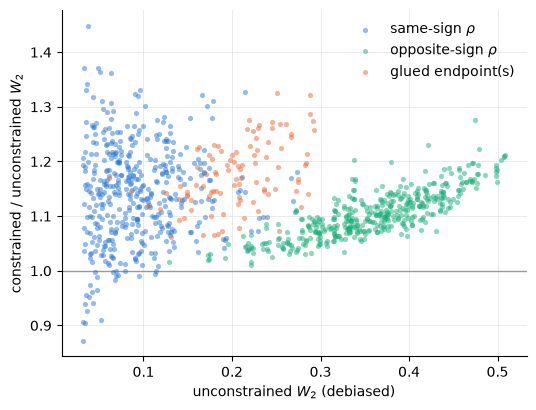

In [31]:
# the same ratio, against the debiased regular W2 itself instead of the rho difference.
# Uses ok / ratio / glued / opposite / other from the matplotlib scatter above.
w2 = pairs.loc[ok, "regular_W2_debiased"]

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.axhline(1, color="0.6", lw=1, zorder=1)               # ratio = 1, the lower bound
for m, color, label in [(other, "#2a78d6", r"same-sign $\rho$"),
                        (opposite, "#1baf7a", r"opposite-sign $\rho$"),
                        (glued, "#eb6834", "glued endpoint(s)")]:
    ax.scatter(w2[m], ratio[m], s=14, color=color, alpha=0.5, linewidths=0, label=label)
ax.set(xlabel="unconstrained $W_2$ (debiased)",
       ylabel="constrained / unconstrained $W_2$")
ax.grid(color="0.9", lw=0.6)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False)
plt.show()